# Quá trình huấn luyện và cải tiến: Baseline → Final (YOLOv8)

Notebook này **ghi lại hành trình** từ mô hình cơ sở đến mô hình cuối dùng trong báo cáo:
- **A0 Baseline:** YOLOv8n, cấu hình tối giản, dữ liệu Roboflow đã chuyển polygon → bbox
- **v2:** YOLOv8s + augment mạnh
- **v3:** fine-tune từ v2, imgsz lớn hơn, xoay 90°, oversample lớp khó
- **v4 (Final):** fine-tune từ v3 + ảnh camera thật đã gán nhãn

Mỗi vòng: **động lực → thay đổi → chỉ số valid ghi nhận → quyết định vòng tiếp**.
Script huấn luyện tương ứng: `train_baseline.py`, `train_v2.py`, `train_v3.py`, `train_v4.py`.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

def find_project() -> Path:
    for cand in [Path.cwd().parents[1], Path.cwd().parent,
                 Path('/home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam')]:
        if (cand / 'notebooks').exists() and (cand / 'train_baseline.py').exists():
            return cand
    return Path.cwd().parents[1]

PROJECT = find_project()
NB = PROJECT / 'notebooks'
EXPORTS = {
    'baseline': NB / 'baseline_exports' / 'baseline_run_meta.json',
    'v2': NB / 'v2_exports' / 'v2_run_meta.json',
    'v3': NB / 'v3_exports' / 'v3_run_meta.json',
    'v4': NB / 'v4_exports' / 'v4_run_meta.json',
}
COMPARE = NB / 'compare_exports'
print('PROJECT =', PROJECT)
for k,v in EXPORTS.items():
    print(k, 'OK' if v.exists() else 'MISSING', v)


PROJECT = /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam
baseline OK /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/notebooks/baseline_exports/baseline_run_meta.json
v2 OK /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/notebooks/v2_exports/v2_run_meta.json
v3 OK /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/notebooks/v3_exports/v3_run_meta.json
v4 OK /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/notebooks/v4_exports/v4_run_meta.json


## 1. Baseline (YOLOv8n)

**Mục tiêu:** tạo mốc so sánh nhanh, tái lập được.

**Thiết lập tiêu biểu:** `yolov8n.pt`, `imgsz=640`, ~50 epoch, dữ liệu `datasets/vn_currency_yolo_bbox`.

**Quan sát sau train:** mAP50 trên valid đã rất cao → miền Roboflow “dễ”; cần cải tiến hướng camera / nhầm lớp chứ không chỉ săn mAP studio.


In [2]:
def load_meta(path: Path):
    if not path.exists():
        return None
    return json.loads(path.read_text(encoding='utf-8'))

metas = {k: load_meta(p) for k,p in EXPORTS.items()}

def val_row(name, meta):
    if not meta or 'val' not in meta:
        return None
    v = meta['val']
    return {
        'version': name,
        'mAP50': v.get('mAP50'),
        'mAP50-95': v.get('mAP50-95'),
        'precision': v.get('precision'),
        'recall': v.get('recall'),
        'imgsz': meta.get('imgsz'),
        'epochs': meta.get('epochs'),
        'model': meta.get('model') or meta.get('version'),
    }

rows = [val_row(k, metas[k]) for k in ['baseline','v2','v3','v4']]
hist = pd.DataFrame([r for r in rows if r])
display(hist)


,version,mAP50,mAP50-95,precision,recall,imgsz,epochs,model
0,baseline,0.994649,0.931480,0.989089,0.995300,640.0,50.0,yolov8n.pt
1,v2,0.993818,0.866929,0.987712,0.998943,640.0,100.0,yolov8s.pt
2,v3,0.994854,0.861327,0.990711,0.998683,800.0,80.0,v3
3,v4,0.993986,0.890809,0.993468,0.997710,NaN,NaN,v4


## 2. Vòng v2 — tăng capacity + augment

**Thay đổi chính**
- Đổi backbone/head sang **YOLOv8s**
- Augment: scale, mosaic, mixup, copy-paste, erasing; tăng trọng số loss phân lớp
- Train dài hơn baseline (~100 epoch)

**Lý do:** baseline đủ tốt trên studio nhưng demo camera còn nhầm / mất dấu; cần sức biểu diễn và đa dạng hóa hình học/ánh sáng giả lập.


In [3]:
v2 = metas.get('v2') or {}
print('v2 keys:', sorted(v2.keys()))
if 'train_aug' in v2:
    display(pd.Series(v2['train_aug'], name='v2_aug'))
if 'val' in v2:
    display(pd.Series(v2['val']))
cmp_v2 = NB / 'v2_exports' / 'compare_baseline_vs_v2_val.csv'
if cmp_v2.exists():
    display(pd.read_csv(cmp_v2))


v2 keys: ['batch', 'best_pt', 'class_names', 'created_at', 'data_yaml', 'device', 'epochs', 'imgsz', 'model', 'run_dir', 'run_name', 'seed', 'targets', 'test', 'train_aug', 'val', 'version']


scale          0.60
mosaic         1.00
mixup          0.15
copy_paste     0.25
erasing        0.25
cls            1.00
hsv_s          0.70
hsv_v          0.50
degrees       12.00
Name: v2_aug, dtype: float64

mAP50          0.993818
mAP50-95       0.866929
precision      0.987712
recall         0.998943
AP50_1000      0.995000
AP50_10000     0.991040
AP50_100000    0.995000
AP50_2000      0.995000
AP50_20000     0.988318
AP50_200000    0.995000
AP50_5000      0.995000
AP50_50000     0.995000
AP50_500000    0.995000
dtype: float64

,model,val_mAP50,val_mAP50-95,val_precision,val_recall
0,baseline_yolov8n,0.994649,0.931480,0.989089,0.995300
1,yolov8s.pt v2 improved,0.993818,0.866929,0.987712,0.998943


## 3. Vòng v3 — nhắm cặp lớp dễ nhầm + độ phân giải

**Thay đổi chính**
- Fine-tune từ trọng số v2
- `imgsz` tăng (ví dụ 800)
- Xoay 90°, oversample các lớp trọng tâm (5k / 20k / 200k / …)
- Dataset yaml riêng nếu có tái lấy mẫu

**Lý do quan sát lỗi:** cặp màu gần (5.000 ↔ 20.000), một số mệnh giá polymer dễ nhầm khi nghiêng/mờ.


In [4]:
v3 = metas.get('v3') or {}
print('finetune_from:', v3.get('finetune_from'))
print('targets:', v3.get('targets'))
print('imgsz/epochs/batch:', v3.get('imgsz'), v3.get('epochs'), v3.get('batch'))
if 'val' in v3:
    display(pd.Series({k:v for k,v in v3['val'].items() if k.startswith('AP50') or k in ['mAP50','mAP50-95','precision','recall']}))
cmp_v3 = NB / 'v3_exports' / 'compare_baseline_v2_v3_val.csv'
if cmp_v3.exists():
    display(pd.read_csv(cmp_v3))


finetune_from: /home/server_02/Documents/dungtv/nhan_dang_tien_Viet_Nam/notebooks/v2_exports/yolov8s_v2_best.pt
targets: ['reduce 5000 ↔ 20000 confusion', 'reduce 100000 ↔ 500000 confusion', 'improve vertical (portrait) banknotes']
imgsz/epochs/batch: 800 80 16


mAP50          0.994854
mAP50-95       0.861327
precision      0.990711
recall         0.998683
AP50_1000      0.995000
AP50_10000     0.993687
AP50_100000    0.995000
AP50_2000      0.995000
AP50_20000     0.995000
AP50_200000    0.995000
AP50_5000      0.995000
AP50_50000     0.995000
AP50_500000    0.995000
dtype: float64

,model,val_mAP50,val_mAP50-95,val_precision,val_recall,AP50_5000,AP50_20000,AP50_100000,AP50_500000
0,baseline,0.994649,0.931480,0.989089,0.995300,NaN,NaN,NaN,NaN
1,v2,0.993818,0.866929,0.987712,0.998943,NaN,NaN,NaN,NaN
2,YOLOv8s v3 (finetune v2 + rot/oversample),0.994854,0.861327,0.990711,0.998683,0.995,0.995,0.995,0.995


## 4. Vòng v4 (Final) — bổ sung ảnh camera thật

**Thay đổi chính**
- Fine-tune từ v3
- Thêm ảnh `real_cam_yolo` (bbox chỉnh tay bằng công cụ Tkinter)
- Giữ focus các lớp còn lỗi trên demo
- Phía suy luận demo: **temporal hold ~1s** giảm nhấp nháy nhãn giữa các frame

**Lý do:** khoảng cách miền (domain gap) giữa ảnh letterbox studio và webcam thực tế là nguyên nhân chính khiến chỉ số Roboflow cao nhưng trải nghiệm demo chưa ổn định.


In [5]:
v4 = metas.get('v4') or {}
print('finetune_from:', v4.get('finetune_from'))
print('focus class ids:', v4.get('focus'))
print('note:', v4.get('note'))
if 'val' in v4:
    display(pd.Series(v4['val']))

# Ảnh camera
real_img = PROJECT / 'datasets' / 'real_cam_yolo' / 'images'
n = len(list(real_img.glob('*'))) if real_img.exists() else 0
print('Số file ảnh trong real_cam_yolo/images:', n)


finetune_from: /home/server_02/Documents/dungtv/nhan_dang_tien_Viet_Nam/notebooks/v3_exports/yolov8s_v3_best.pt
focus class ids: [5, 6, 4, 2, 7]
note: Kèm demo temporal smooth để giảm mất nhận dạng 50k/100k giữa các frame


mAP50          0.993986
mAP50-95       0.890809
precision      0.993468
recall         0.997710
AP50_1000      0.995000
AP50_10000     0.994095
AP50_100000    0.995000
AP50_2000      0.995000
AP50_20000     0.986777
AP50_200000    0.995000
AP50_5000      0.995000
AP50_50000     0.995000
AP50_500000    0.995000
dtype: float64

Số file ảnh trong real_cam_yolo/images: 18


## 5. Tổng hợp đường cong / lịch sử chỉ số đã lưu

Đọc file so sánh đã xuất từ notebook `06_Compare` (nếu có) để nhìn toàn cảnh trước khi sang notebook đánh giá công bằng.


,model,val_mAP50,val_mAP50-95,val_precision,val_recall,source
0,A0 baseline,0.994649,0.931480,0.989089,0.995300,baseline_val_metrics.csv
1,v2,0.993818,0.866929,0.987712,0.998943,v2_val_metrics.csv
2,v3,0.994854,0.861327,0.990711,0.998683,v3_val_metrics.csv
3,v4 final,0.993986,0.890809,0.993468,0.997710,v4_val_metrics.csv


,model,selected_by,val_mAP50,val_mAP50-95,test_mAP50,test_mAP50-95,test_P,test_R,test_F1,note
0,Baseline YOLOv8n (A0),val during train,0.994649,0.930973,0.991928,0.919345,0.994692,0.995297,0.994994,mốc
1,Final YOLOv8s v4,val during iterative improve,0.994911,0.894110,0.991834,0.882278,0.991043,0.996545,0.993786,aug + capacity + real-cam data


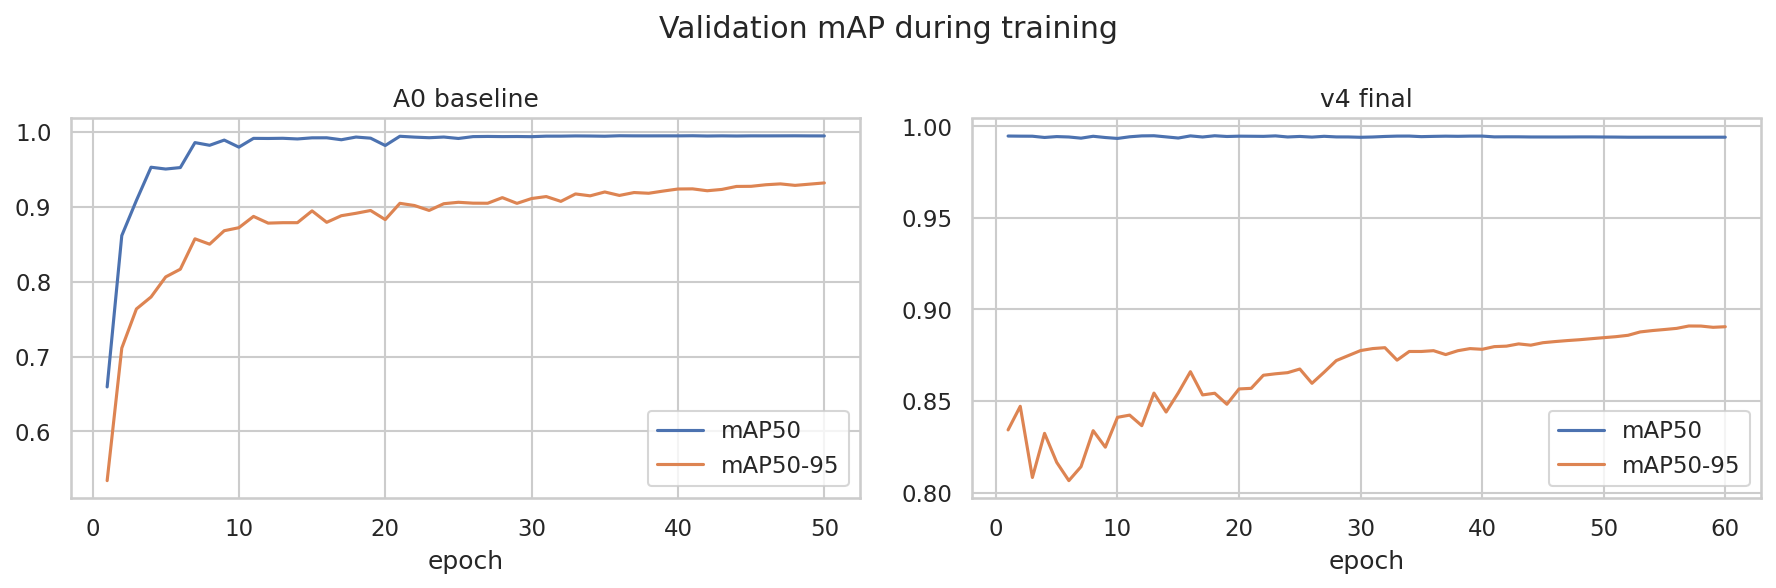

In [6]:
hist_csv = COMPARE / 'saved_train_val_metrics_history.csv'
report_tbl = COMPARE / 'report_table_baseline_vs_final.csv'
fig = COMPARE / 'fig_train_curves.png'

if hist_csv.exists():
    dfh = pd.read_csv(hist_csv)
    display(dfh.head(20))
else:
    print('Chưa có saved_train_val_metrics_history.csv — dùng bảng hist ở trên.')

if report_tbl.exists():
    display(pd.read_csv(report_tbl))

if fig.exists():
    from IPython.display import Image, display as idisplay
    idisplay(Image(filename=str(fig)))
else:
    # Vẽ nhanh từ hist nếu đủ cột
    if len(hist):
        fig2, ax = plt.subplots(1, 2, figsize=(10, 3.5))
        ax[0].bar(hist['version'], hist['mAP50'], color='steelblue')
        ax[0].set_ylim(0.97, 1.0)
        ax[0].set_title('val mAP50 theo vòng')
        ax[1].bar(hist['version'], hist['mAP50-95'], color='darkorange')
        ax[1].set_title('val mAP50-95 theo vòng')
        plt.tight_layout()
        plt.show()


## 6. Kết luận quá trình cải tiến

| Vòng | Thêm | Bớt / giữ nguyên | Thành quả mang lại |
|------|------|------------------|--------------------|
| Baseline | Pipeline bbox thống nhất | Chưa tối ưu augment/camera | Mốc mAP cao trên Roboflow |
| v2 | YOLOv8s + augment mạnh | Không còn chỉ dựa nano | Tăng capacity & đa dạng mẫu giả lập |
| v3 | imgsz↑, xoay, oversample lớp khó | Fine-tune thay vì train lại từ đầu | Nhắm nhầm cặp màu gần |
| v4 | Ảnh cam thật + chỉnh bbox | Không thay protocol test Roboflow | Thích nghi demo thực tế |

Notebook tiếp theo (`03_So_sanh_Baseline_vs_Final.ipynb`) đánh giá **công bằng** baseline vs final trên cùng split/imgsz/conf và quét ngưỡng theo chi phí.
